# Stock Prices Dataset — Data Preprocessing

## Project Objective

The objective is to inspect and prepare the stock-prices dataset for a future machine-learning workflow. This notebook covers data-quality assessment, missing-value handling, investigation of unusual price records, feature engineering, and construction of a reusable preprocessing pipeline.

**Scope:** This is a preprocessing task only. No prediction target is defined, and no model is trained or evaluated.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


## Libraries and Dataset Loading

The notebook uses Pandas and NumPy for data manipulation, Matplotlib and Seaborn for visualization, and scikit-learn for preprocessing. The CSV file is uploaded and loaded into a Pandas DataFrame.

In [ ]:
from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")

Saving 2) Stock Prices Data Set.csv to 2) Stock Prices Data Set.csv
Dataset loaded successfully!


## Initial Data Exploration

The first inspection checks the dataset dimensions, columns, data types, summary statistics, missing values, and duplicate records.

The dataset contains **497,472 rows and 7 columns**: `symbol`, `date`, `open`, `high`, `low`, `close`, and `volume`. There are **11 missing values in `open`, 8 in `high`, and 8 in `low`**. No exact duplicate rows or duplicate `symbol`–`date` pairs were detected.

In [ ]:
# Display first 5 rows
display(df.head())

# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Data types
print("\nData Types:")
print(df.dtypes)

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

,symbol,date,open,high,low,close,volume
0,AAL,2014-01-02,25.0700,25.8200,25.0600,25.3600,8998943
1,AAPL,2014-01-02,79.3828,79.5756,78.8601,79.0185,58791957
2,AAP,2014-01-02,110.3600,111.8800,109.2900,109.7400,542711
3,ABBV,2014-01-02,52.1200,52.3300,51.5200,51.9800,4569061
4,ABC,2014-01-02,70.1100,70.2300,69.4800,69.8900,1148391


Dataset Shape: (497472, 7)

Columns:
['symbol', 'date', 'open', 'high', 'low', 'close', 'volume']

Data Types:
symbol     object
date       object
open      float64
high      float64
low       float64
close     float64
volume      int64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 497472 entries, 0 to 497471
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   symbol  497472 non-null  object 
 1   date    497472 non-null  object 
 2   open    497461 non-null  float64
 3   high    497464 non-null  float64
 4   low     497464 non-null  float64
 5   close   497472 non-null  float64
 6   volume  497472 non-null  int64  
dtypes: float64(4), int64(1), object(2)
memory usage: 26.6+ MB

Statistical Summary:


,open,high,low,close,volume
count,497461.000000,497464.000000,497464.000000,497472.000000,4.974720e+05
mean,86.352275,87.132562,85.552467,86.369082,4.253611e+06
std,101.471228,102.312062,100.570957,101.472407,8.232139e+06
min,1.620000,1.690000,1.500000,1.590000,0.000000e+00
25%,41.690000,42.090000,41.280000,41.703750,1.080166e+06
50%,64.970000,65.560000,64.353700,64.980000,2.084896e+06
75%,98.410000,99.230000,97.580000,98.420000,4.271928e+06
max,2044.000000,2067.990000,2035.110000,2049.000000,6.182376e+08


In [ ]:
missing_values = df.isnull().sum()

missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

missing_report = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})

display(missing_report)

,Missing Values,Missing Percentage
symbol,0,0.000000
date,0,0.000000
open,11,0.002211
high,8,0.001608
low,8,0.001608
close,0,0.000000
volume,0,0.000000


In [ ]:
# Check exact duplicate rows
exact_duplicates = df.duplicated().sum()

print("Exact Duplicate Rows:", exact_duplicates)

# Check duplicate stock-date combinations
stock_date_duplicates = df.duplicated(
    subset=['symbol', 'date']
).sum()

print("Duplicate Stock-Date Records:", stock_date_duplicates)

Exact Duplicate Rows: 0
Duplicate Stock-Date Records: 0


### Date Format Conversion

The `date` column is converted to Pandas datetime format to support chronological sorting and date-based feature extraction. The conversion produced **zero invalid dates**. The observed date range is **2014-01-02 to 2017-12-29**.

In [ ]:
# Convert date column to datetime
df['date'] = pd.to_datetime(
    df['date'],
    errors='coerce'
)

print("Date Data Type:", df['date'].dtype)

print("Invalid Dates:", df['date'].isna().sum())

print("Date Range:")
print("Start:", df['date'].min())
print("End:", df['date'].max())

Date Data Type: datetime64[ns]
Invalid Dates: 0
Date Range:
Start: 2014-01-02 00:00:00
End: 2017-12-29 00:00:00


## Price and Volume Quality Checks

The OHLC values are checked for basic consistency: `high` should not be below `low`, while `open` and `close` are checked against the High–Low interval. Volume is checked for negative and zero values.

The initial scan found 1 high/low issue, 4 open-range issues, 9 close-range issues, no negative volumes, and 4 zero-volume records. These are indicators for further investigation, not automatic proof that every flagged value is incorrect. Adjusted and unadjusted price conventions may affect OHLC comparisons.

In [ ]:
# Check invalid price relationships

invalid_high_low = (df['high'] < df['low']).sum()

invalid_open = (
    (df['open'] < df['low']) |
    (df['open'] > df['high'])
).sum()

invalid_close = (
    (df['close'] < df['low']) |
    (df['close'] > df['high'])
).sum()

negative_volume = (df['volume'] < 0).sum()

zero_volume = (df['volume'] == 0).sum()

print("High < Low:", invalid_high_low)
print("Open outside High-Low range:", invalid_open)
print("Close outside High-Low range:", invalid_close)
print("Negative Volume:", negative_volume)
print("Zero Volume:", zero_volume)

High < Low: 1
Open outside High-Low range: 4
Close outside High-Low range: 9
Negative Volume: 0
Zero Volume: 4


In [ ]:
df = df.sort_values(
    by=['symbol', 'date']
).reset_index(drop=True)

In [ ]:
# Find rows where High is lower than Low
problem_high_low = df[df['high'] < df['low']]

# Find rows where Open is outside High-Low range
problem_open = df[
    (df['open'] < df['low']) |
    (df['open'] > df['high'])
]

# Find rows where Close is outside High-Low range
problem_close = df[
    (df['close'] < df['low']) |
    (df['close'] > df['high'])
]

# Find rows with zero trading volume
zero_volume_rows = df[df['volume'] == 0]

print("High < Low Records:")
display(problem_high_low)

print("Open Outside Range:")
display(problem_open)

print("Close Outside Range:")
display(problem_close)

print("Zero Volume Records:")
display(zero_volume_rows)

High < Low Records:


,symbol,date,open,high,low,close,volume
43395,AOS,2014-05-19,23.89,23.595,23.85,24.445,1944854


Open Outside Range:


,symbol,date,open,high,low,close,volume
43395,AOS,2014-05-19,23.89,23.5950,23.850,24.445,1944854
91809,CHD,2014-05-19,18.77,33.9525,33.695,33.895,1078888
133750,DHR,2014-11-06,78.47,81.3050,80.490,81.260,1614419
343831,O,2014-11-06,44.74,47.5700,46.730,46.860,1803132


Close Outside Range:


,symbol,date,open,high,low,close,volume
43395,AOS,2014-05-19,23.890,23.595,23.850,24.4450,1944854
63004,BBY,2016-03-14,33.550,33.750,33.080,32.7200,6037794
92845,CHK,2014-06-30,30.430,31.100,30.370,29.3900,8132836
242487,IP,2014-07-01,50.850,51.070,50.570,50.0900,5624981
281857,LNT,2016-05-19,35.190,35.785,35.085,17.8700,1231722
343781,O,2014-08-27,44.675,44.700,44.660,44.5272,185518
413567,SPG,2014-05-28,176.230,176.600,174.500,165.4200,1383759
446598,UA,2016-06-10,35.750,36.410,35.700,35.5400,616887
480948,WRK,2016-05-13,42.450,42.890,41.820,38.3900,2153541


Zero Volume Records:


,symbol,date,open,high,low,close,volume
134036,DHR,2016-01-12,NaN,NaN,NaN,88.55,0
193471,FTV,2016-07-01,NaN,NaN,NaN,49.54,0
344117,O,2016-01-12,NaN,NaN,NaN,52.43,0
446553,UA,2016-04-07,NaN,NaN,NaN,41.56,0


In [ ]:
problem_mask = (
    (df['high'] < df['low']) |
    (df['open'] < df['low']) |
    (df['open'] > df['high']) |
    (df['close'] < df['low']) |
    (df['close'] > df['high'])
)

print("Total Unique Rows with Price Issues:", problem_mask.sum())
print("Total Rows with Zero Volume:", (df['volume'] == 0).sum())

Total Unique Rows with Price Issues: 12
Total Rows with Zero Volume: 4


In [ ]:
df = df.sort_values(
    by=['symbol', 'date']
).reset_index(drop=True)

display(df.head())

,symbol,date,open,high,low,close,volume
0,A,2014-01-02,57.10,57.100,56.15,56.21,1916160
1,A,2014-01-03,56.39,57.345,56.26,56.92,1866651
2,A,2014-01-06,57.40,57.700,56.56,56.64,1777472
3,A,2014-01-07,56.95,57.630,56.93,57.45,1463208
4,A,2014-01-08,57.33,58.540,57.17,58.39,2659468


## Investigating Missing Values

Missing records are examined by stock, date, and missing-column pattern. Neighboring records are also inspected to understand the context of each missing observation.

The dataset contains **11 rows with missing values**. All 11 have a missing `open` value; 8 also have missing `high` and `low`. The `close` and `volume` columns contain no missing values.

In [ ]:
# Extract all rows containing missing values
missing_rows = df[df.isnull().any(axis=1)].copy()

print("Total Rows with Missing Values:", len(missing_rows))

display(missing_rows)

Total Rows with Missing Values: 11


,symbol,date,open,high,low,close,volume
66487,BHF,2017-07-26,NaN,NaN,NaN,69.0842,3
133913,DHR,2015-07-17,NaN,88.76,88.24,88.7200,2056819
134036,DHR,2016-01-12,NaN,NaN,NaN,88.5500,0
162370,ES,2015-07-17,NaN,48.49,47.85,47.9200,1246786
193471,FTV,2016-07-01,NaN,NaN,NaN,49.5400,0
343994,O,2015-07-17,NaN,47.31,46.83,46.9900,1229513
344117,O,2016-01-12,NaN,NaN,NaN,52.4300,0
386638,REGN,2015-06-09,NaN,NaN,NaN,526.0900,12135
446553,UA,2016-04-07,NaN,NaN,NaN,41.5600,0
468479,VRTX,2015-05-12,NaN,NaN,NaN,124.0800,569747


In [ ]:
# Count missing values for each stock
missing_by_stock = (
    df.groupby('symbol')
    .apply(lambda group: group.isnull().sum().sum())
)

missing_by_stock = missing_by_stock[
    missing_by_stock > 0
].sort_values(ascending=False)

display(missing_by_stock)

,0
symbol,
DHR,4
O,4
BHF,3
FTV,3
REGN,3
VRTX,3
UA,3
WRK,3
ES,1


In [ ]:
# Missing values per date
missing_by_date = df[
    df.isnull().any(axis=1)
].groupby('date').size()

print("Dates Containing Missing Values:")
display(missing_by_date)

Dates Containing Missing Values:


,0
date,
2015-05-12,1
2015-06-09,1
2015-06-26,1
2015-07-17,3
2016-01-12,2
2016-04-07,1
2016-07-01,1
2017-07-26,1


In [ ]:
# Select rows containing missing values
missing_rows = df[df.isnull().any(axis=1)].copy()

# Identify which columns are missing in each row
missing_patterns = missing_rows[
    ['open', 'high', 'low', 'close', 'volume']
].isnull()

# Create a readable report
pattern_report = missing_rows[['symbol', 'date', 'volume']].copy()

pattern_report['Missing Columns'] = missing_patterns.apply(
    lambda row: ', '.join(row.index[row]),
    axis=1
)

display(pattern_report)

,symbol,date,volume,Missing Columns
66487,BHF,2017-07-26,3,"open, high, low"
133913,DHR,2015-07-17,2056819,open
134036,DHR,2016-01-12,0,"open, high, low"
162370,ES,2015-07-17,1246786,open
193471,FTV,2016-07-01,0,"open, high, low"
343994,O,2015-07-17,1229513,open
344117,O,2016-01-12,0,"open, high, low"
386638,REGN,2015-06-09,12135,"open, high, low"
446553,UA,2016-04-07,0,"open, high, low"
468479,VRTX,2015-05-12,569747,"open, high, low"


In [ ]:
# Inspect neighboring records for each missing row
for idx, row in missing_rows.iterrows():

    stock_data = df[df['symbol'] == row['symbol']]

    previous_rows = stock_data[
        stock_data['date'] < row['date']
    ].tail(1)

    next_rows = stock_data[
        stock_data['date'] > row['date']
    ].head(1)

    print(f"\nStock: {row['symbol']} | Date: {row['date']}")

    print("Previous Record:")
    display(previous_rows)

    print("Current Record:")
    display(df.loc[[idx]])

    print("Next Record:")
    display(next_rows)


Stock: BHF | Date: 2017-07-26 00:00:00
Previous Record:


,symbol,date,open,high,low,close,volume
66486,BHF,2017-07-25,69.1461,69.1461,68.95,69.0842,1362


Current Record:


,symbol,date,open,high,low,close,volume
66487,BHF,2017-07-26,NaN,NaN,NaN,69.0842,3


Next Record:


,symbol,date,open,high,low,close,volume
66488,BHF,2017-07-27,69.25,69.25,68.0,68.0,12970


... (56 outputs left out)

Current Record:


,symbol,date,open,high,low,close,volume
480726,WRK,2015-06-26,NaN,NaN,NaN,61.9,100


Next Record:


,symbol,date,open,high,low,close,volume
480727,WRK,2015-06-29,60.92,60.92,60.8,60.8,300


## Missing-Value Handling

The original dataset state is preserved in `df_raw`, and cleaning is performed on a separate copy named `clean_df`.

Rows missing any OHLC value are removed rather than imputing stock prices without reliable evidence. Only **11 of 497,472 rows** are affected (approximately **0.0022%**). After removal, `clean_df` contains **497,461 rows** and no missing values.

In [ ]:
# Preserve the original dataset
df_raw = df.copy()

print("Original Dataset Shape:", df_raw.shape)

Original Dataset Shape: (497472, 7)


In [ ]:
# Create a working copy
clean_df = df_raw.copy()

# Identify rows with missing OHLC values
ohlc_columns = ['open', 'high', 'low', 'close']

missing_ohlc_mask = clean_df[ohlc_columns].isnull().any(axis=1)

# Count rows before removal
rows_before = len(clean_df)

# Remove rows with missing OHLC values
clean_df = clean_df.loc[~missing_ohlc_mask].copy()

# Count rows after removal
rows_after = len(clean_df)

print("Rows Before Cleaning:", rows_before)
print("Removed Rows:", rows_before - rows_after)
print("Rows After Cleaning:", rows_after)
print("Remaining Missing Values:", clean_df.isnull().sum().sum())

Rows Before Cleaning: 497472
Removed Rows: 11
Rows After Cleaning: 497461
Remaining Missing Values: 0


## Price-Anomaly Flags and Diagnostic Review

Three Boolean flags identify records where `high < low`, `open` falls outside the High–Low interval, or `close` falls outside that interval.

After missing OHLC rows are removed, **12 unique records** have at least one price flag: 1 high/low issue, 4 open-range issues, and 9 close-range issues. One record triggers multiple flags.

The diagnostic table helps inspect the size of the discrepancies. These records are **retained and documented**, not automatically corrected or deleted. Their validity should be checked against the dataset's price-adjustment methodology. The quality flags are for auditing and are excluded from the model features later.

In [ ]:
# Create data quality flags

clean_df['invalid_high_low'] = (
    clean_df['high'] < clean_df['low']
)

clean_df['invalid_open'] = (
    (clean_df['open'] < clean_df['low']) |
    (clean_df['open'] > clean_df['high'])
)

clean_df['invalid_close'] = (
    (clean_df['close'] < clean_df['low']) |
    (clean_df['close'] > clean_df['high'])
)

# Count flagged records
print("High < Low:", clean_df['invalid_high_low'].sum())

print("Open Outside Range:", clean_df['invalid_open'].sum())

print("Close Outside Range:", clean_df['invalid_close'].sum())

# Display all flagged records
price_issues = clean_df[
    clean_df[
        ['invalid_high_low', 'invalid_open', 'invalid_close']
    ].any(axis=1)
]

display(price_issues)

High < Low: 1
Open Outside Range: 4
Close Outside Range: 9


,symbol,date,open,high,low,close,volume,invalid_high_low,invalid_open,invalid_close
43395,AOS,2014-05-19,23.890,23.5950,23.850,24.4450,1944854,True,True,True
63004,BBY,2016-03-14,33.550,33.7500,33.080,32.7200,6037794,False,False,True
91809,CHD,2014-05-19,18.770,33.9525,33.695,33.8950,1078888,False,True,False
92845,CHK,2014-06-30,30.430,31.1000,30.370,29.3900,8132836,False,False,True
133750,DHR,2014-11-06,78.470,81.3050,80.490,81.2600,1614419,False,True,False
242487,IP,2014-07-01,50.850,51.0700,50.570,50.0900,5624981,False,False,True
281857,LNT,2016-05-19,35.190,35.7850,35.085,17.8700,1231722,False,False,True
343781,O,2014-08-27,44.675,44.7000,44.660,44.5272,185518,False,False,True
343831,O,2014-11-06,44.740,47.5700,46.730,46.8600,1803132,False,True,False
413567,SPG,2014-05-28,176.230,176.6000,174.500,165.4200,1383759,False,False,True


In [ ]:
# Create a separate diagnostic table
price_diagnostics = price_issues[
    ['symbol', 'date', 'open', 'high', 'low', 'close', 'volume']
].copy()

# Calculate how far Close is outside the High-Low range
price_diagnostics['close_vs_high'] = (
    price_diagnostics['close'] - price_diagnostics['high']
)

price_diagnostics['close_vs_low'] = (
    price_diagnostics['close'] - price_diagnostics['low']
)

# Calculate relative difference from the nearest boundary
price_diagnostics['close_deviation_pct'] = np.where(
    price_diagnostics['close'] > price_diagnostics['high'],
    ((price_diagnostics['close'] - price_diagnostics['high'])
     / price_diagnostics['high']) * 100,

    np.where(
        price_diagnostics['close'] < price_diagnostics['low'],
        ((price_diagnostics['low'] - price_diagnostics['close'])
         / price_diagnostics['low']) * 100,
        0
    )
)

display(price_diagnostics.round(3))

,symbol,date,open,high,low,close,volume,close_vs_high,close_vs_low,close_deviation_pct
43395,AOS,2014-05-19,23.890,23.595,23.850,24.445,1944854,0.850,0.595,3.602
63004,BBY,2016-03-14,33.550,33.750,33.080,32.720,6037794,-1.030,-0.360,1.088
91809,CHD,2014-05-19,18.770,33.952,33.695,33.895,1078888,-0.057,0.200,0.000
92845,CHK,2014-06-30,30.430,31.100,30.370,29.390,8132836,-1.710,-0.980,3.227
133750,DHR,2014-11-06,78.470,81.305,80.490,81.260,1614419,-0.045,0.770,0.000
242487,IP,2014-07-01,50.850,51.070,50.570,50.090,5624981,-0.980,-0.480,0.949
281857,LNT,2016-05-19,35.190,35.785,35.085,17.870,1231722,-17.915,-17.215,49.067
343781,O,2014-08-27,44.675,44.700,44.660,44.527,185518,-0.173,-0.133,0.297
343831,O,2014-11-06,44.740,47.570,46.730,46.860,1803132,-0.710,0.130,0.000
413567,SPG,2014-05-28,176.230,176.600,174.500,165.420,1383759,-11.180,-9.080,5.203


In [ ]:
# Count records with at least one price issue
flag_columns = [
    'invalid_high_low',
    'invalid_open',
    'invalid_close'
]

price_issue_mask = clean_df[flag_columns].any(axis=1)

print("Total Price Issue Records:", price_issue_mask.sum())

# Count records by issue type
for col in flag_columns:
    print(f"{col}: {clean_df[col].sum()}")

# Count records with multiple simultaneous issues
issues_per_row = clean_df[flag_columns].sum(axis=1)

print("\nRecords with multiple issues:")
print((issues_per_row > 1).sum())

# Display final report
display(
    clean_df.loc[price_issue_mask,
                 ['symbol', 'date', 'open', 'high', 'low', 'close',
                  'volume'] + flag_columns]
)

Total Price Issue Records: 12
invalid_high_low: 1
invalid_open: 4
invalid_close: 9

Records with multiple issues:
1


,symbol,date,open,high,low,close,volume,invalid_high_low,invalid_open,invalid_close
43395,AOS,2014-05-19,23.890,23.5950,23.850,24.4450,1944854,True,True,True
63004,BBY,2016-03-14,33.550,33.7500,33.080,32.7200,6037794,False,False,True
91809,CHD,2014-05-19,18.770,33.9525,33.695,33.8950,1078888,False,True,False
92845,CHK,2014-06-30,30.430,31.1000,30.370,29.3900,8132836,False,False,True
133750,DHR,2014-11-06,78.470,81.3050,80.490,81.2600,1614419,False,True,False
242487,IP,2014-07-01,50.850,51.0700,50.570,50.0900,5624981,False,False,True
281857,LNT,2016-05-19,35.190,35.7850,35.085,17.8700,1231722,False,False,True
343781,O,2014-08-27,44.675,44.7000,44.660,44.5272,185518,False,False,True
343831,O,2014-11-06,44.740,47.5700,46.730,46.8600,1803132,False,True,False
413567,SPG,2014-05-28,176.230,176.6000,174.500,165.4200,1383759,False,False,True


## Date-Based Feature Engineering

A separate dataset, `prepared_df`, is created from the cleaned data. The date is decomposed into `year`, `month`, `day`, and `day_of_week` so that temporal information can be used in later analysis or modeling.

Pandas represents weekdays from **Monday = 0** through **Sunday = 6**.

In [ ]:
# Create a separate feature-preparation dataset
prepared_df = clean_df.copy()

# Extract date-based features
prepared_df['year'] = prepared_df['date'].dt.year
prepared_df['month'] = prepared_df['date'].dt.month
prepared_df['day'] = prepared_df['date'].dt.day
prepared_df['day_of_week'] = prepared_df['date'].dt.dayofweek

# Display the new features
display(
    prepared_df[
        ['symbol', 'date', 'year', 'month', 'day', 'day_of_week']
    ].head()
)

,symbol,date,year,month,day,day_of_week
0,A,2014-01-02,2014,1,2,3
1,A,2014-01-03,2014,1,3,4
2,A,2014-01-06,2014,1,6,0
3,A,2014-01-07,2014,1,7,1
4,A,2014-01-08,2014,1,8,2


## Trading-Volume Distribution and Transformation

Trading volume is strongly right-skewed, with an original skewness of approximately **10.32**. A `log1p` transformation creates `volume_log` using `log(1 + volume)`, which is also safe when volume is zero.

The transformed skewness is approximately **0.40**, indicating that the transformation substantially reduces the right skew. The original `volume` column is retained during inspection; the transformed feature is used in the feature dataset.

Volume Statistics:


,volume
count,4.974610e+05
mean,4.253695e+06
std,8.232210e+06
min,1.010000e+02
25%,1.080183e+06
50%,2.085013e+06
75%,4.271999e+06
max,6.182376e+08


Volume Skewness:
10.322247251651817


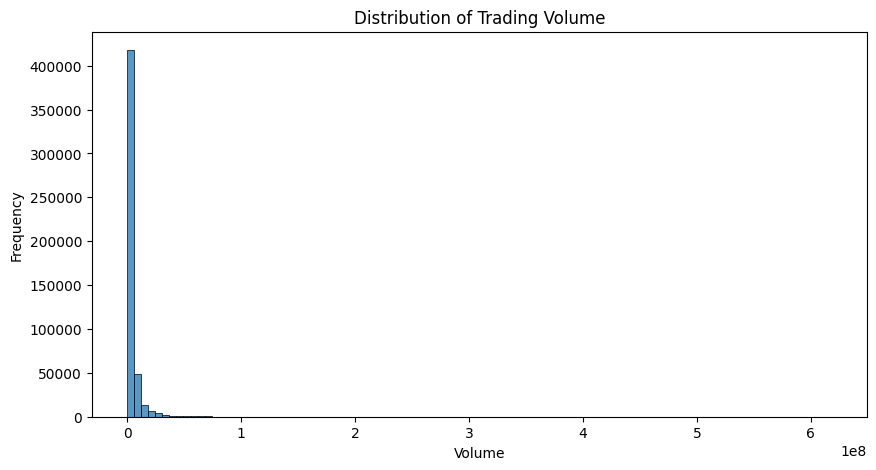

In [ ]:
print("Volume Statistics:")
display(prepared_df['volume'].describe())

print("Volume Skewness:")
print(prepared_df['volume'].skew())

plt.figure(figsize=(10, 5))
sns.histplot(prepared_df['volume'], bins=100)
plt.title('Distribution of Trading Volume')
plt.xlabel('Volume')
plt.ylabel('Frequency')
plt.show()

In [ ]:
# Apply logarithmic transformation to trading volume
prepared_df['volume_log'] = np.log1p(prepared_df['volume'])

# Compare original and transformed statistics
print("Original Volume Statistics:")
display(prepared_df['volume'].describe())

print("\nLog-Transformed Volume Statistics:")
display(prepared_df['volume_log'].describe())

print("\nOriginal Volume Skewness:")
print(prepared_df['volume'].skew())

print("\nTransformed Volume Skewness:")
print(prepared_df['volume_log'].skew())

Original Volume Statistics:


,volume
count,4.974610e+05
mean,4.253695e+06
std,8.232210e+06
min,1.010000e+02
25%,1.080183e+06
50%,2.085013e+06
75%,4.271999e+06
max,6.182376e+08



Log-Transformed Volume Statistics:


,volume_log
count,497461.000000
mean,14.620892
std,1.050445
min,4.624973
25%,13.892642
50%,14.550286
75%,15.267593
max,20.242383



Original Volume Skewness:
10.322247251651817

Transformed Volume Skewness:
0.40069698941528126


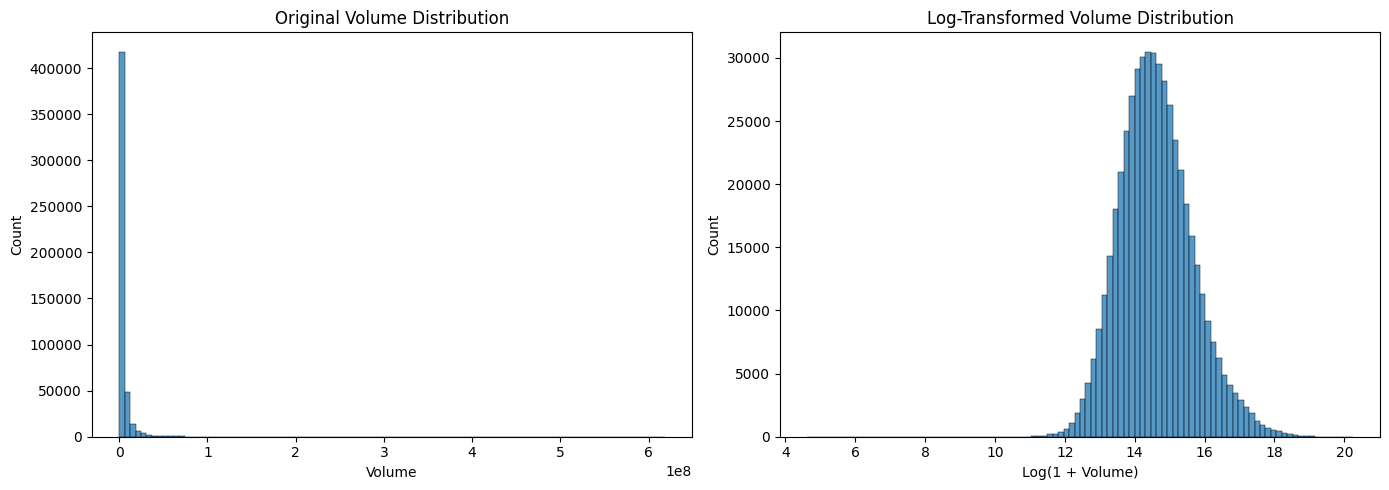

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    prepared_df['volume'],
    bins=100,
    ax=axes[0]
)

axes[0].set_title('Original Volume Distribution')
axes[0].set_xlabel('Volume')

sns.histplot(
    prepared_df['volume_log'],
    bins=100,
    ax=axes[1]
)

axes[1].set_title('Log-Transformed Volume Distribution')
axes[1].set_xlabel('Log(1 + Volume)')

plt.tight_layout()
plt.show()

## Cyclical Encoding of Calendar Features

Month and weekday are cyclical: December is adjacent to January, and Sunday is adjacent to Monday. Encoding them as ordinary integers would not represent these relationships well.

Sine and cosine pairs are therefore created:
- `month_sin` and `month_cos` represent the 12-month cycle.
- `weekday_sin` and `weekday_cos` represent the 7-day cycle.

In [ ]:
# Cyclical encoding for month
prepared_df['month_sin'] = np.sin(
    2 * np.pi * prepared_df['month'] / 12
)

prepared_df['month_cos'] = np.cos(
    2 * np.pi * prepared_df['month'] / 12
)

# Cyclical encoding for day of week
prepared_df['weekday_sin'] = np.sin(
    2 * np.pi * prepared_df['day_of_week'] / 7
)

prepared_df['weekday_cos'] = np.cos(
    2 * np.pi * prepared_df['day_of_week'] / 7
)

display(
    prepared_df[
        ['date', 'month_sin', 'month_cos',
         'weekday_sin', 'weekday_cos']
    ].head()
)

,date,month_sin,month_cos,weekday_sin,weekday_cos
0,2014-01-02,0.5,0.866025,0.433884,-0.900969
1,2014-01-03,0.5,0.866025,-0.433884,-0.900969
2,2014-01-06,0.5,0.866025,0.000000,1.000000
3,2014-01-07,0.5,0.866025,0.781831,0.623490
4,2014-01-08,0.5,0.866025,0.974928,-0.222521


## Preparing the Feature Dataset

After extracting date features, the raw `date`, `month`, `day`, `day_of_week`, and original `volume` columns are removed. A separate `features_df` is created, and the three data-quality flags are excluded from the model inputs.

The resulting dataset contains **11 features**: `symbol`, four OHLC price columns, `year`, `volume_log`, and four cyclical date features. `symbol` is categorical; the remaining 10 features are numerical.

In [ ]:
model_df = prepared_df.copy()

columns_to_drop = [
    'date',
    'month',
    'day',
    'day_of_week',
    'volume'
]

model_df = model_df.drop(columns=columns_to_drop)

print("Dataset Shape:", model_df.shape)

display(model_df.head())

print("\nData Types:")
print(model_df.dtypes)

Dataset Shape: (497461, 14)


,symbol,open,high,low,close,invalid_high_low,invalid_open,invalid_close,year,volume_log,month_sin,month_cos,weekday_sin,weekday_cos
0,A,57.10,57.100,56.15,56.21,False,False,False,2014,14.465834,0.5,0.866025,0.433884,-0.900969
1,A,56.39,57.345,56.26,56.92,False,False,False,2014,14.439657,0.5,0.866025,-0.433884,-0.900969
2,A,57.40,57.700,56.56,56.64,False,False,False,2014,14.390703,0.5,0.866025,0.000000,1.000000
3,A,56.95,57.630,56.93,57.45,False,False,False,2014,14.196143,0.5,0.866025,0.781831,0.623490
4,A,57.33,58.540,57.17,58.39,False,False,False,2014,14.793637,0.5,0.866025,0.974928,-0.222521



Data Types:
symbol               object
open                float64
high                float64
low                 float64
close               float64
invalid_high_low       bool
invalid_open           bool
invalid_close          bool
year                  int32
volume_log          float64
month_sin           float64
month_cos           float64
weekday_sin         float64
weekday_cos         float64
dtype: object


In [ ]:
# Create a separate copy for feature preparation
features_df = model_df.copy()

# Remove data quality flags from model features
quality_flags = [
    'invalid_high_low',
    'invalid_open',
    'invalid_close'
]

features_df = features_df.drop(columns=quality_flags)

print("Features Dataset Shape:", features_df.shape)

print("\nRemaining Data Types:")
print(features_df.dtypes)

display(features_df.head())

Features Dataset Shape: (497461, 11)

Remaining Data Types:
symbol          object
open           float64
high           float64
low            float64
close          float64
year             int32
volume_log     float64
month_sin      float64
month_cos      float64
weekday_sin    float64
weekday_cos    float64
dtype: object


,symbol,open,high,low,close,year,volume_log,month_sin,month_cos,weekday_sin,weekday_cos
0,A,57.10,57.100,56.15,56.21,2014,14.465834,0.5,0.866025,0.433884,-0.900969
1,A,56.39,57.345,56.26,56.92,2014,14.439657,0.5,0.866025,-0.433884,-0.900969
2,A,57.40,57.700,56.56,56.64,2014,14.390703,0.5,0.866025,0.000000,1.000000
3,A,56.95,57.630,56.93,57.45,2014,14.196143,0.5,0.866025,0.781831,0.623490
4,A,57.33,58.540,57.17,58.39,2014,14.793637,0.5,0.866025,0.974928,-0.222521


## Duplicate Records Investigation

The feature dataset reports **2 duplicated rows**, involving 4 records. However, the prepared dataset has zero exact duplicate rows and zero duplicated `symbol`–`date` pairs.

The apparent duplicates occur because the exact date was removed and the retained year/month/weekday features do not uniquely identify each trading date. The records belong to different dates (ALL: 2017-12-15 and 2017-12-22; HON: 2017-08-22 and 2017-08-29).

**Decision:** No rows are removed because these are distinct observations, not duplicate source records.

In [ ]:
# Check missing values
print("Missing Values:")
print(features_df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:")
print(features_df.duplicated().sum())

# Check numerical statistics
print("\nNumerical Statistics:")
display(features_df.describe())

# Check categorical values
print("\nNumber of Unique Stocks:")
print(features_df['symbol'].nunique())

Missing Values:
symbol         0
open           0
high           0
low            0
close          0
year           0
volume_log     0
month_sin      0
month_cos      0
weekday_sin    0
weekday_cos    0
dtype: int64

Duplicate Rows:
2

Numerical Statistics:


,open,high,low,close,year,volume_log,month_sin,month_cos,weekday_sin,weekday_cos
count,497461.000000,497461.000000,497461.000000,497461.000000,497461.000000,497461.000000,4.974610e+05,4.974610e+05,497461.000000,497461.000000
mean,86.352275,87.132717,85.552616,86.368586,2015.512573,14.620892,-1.209237e-02,-9.810398e-03,0.362931,-0.092632
std,101.471228,102.312340,100.571231,101.471516,1.117420,1.050445,7.075533e-01,7.064898e-01,0.515545,0.770659
min,1.620000,1.690000,1.500000,1.590000,2014.000000,4.624973,-1.000000e+00,-1.000000e+00,-0.433884,-0.900969
25%,41.690000,42.090000,41.280000,41.700000,2015.000000,13.892642,-8.660254e-01,-8.660254e-01,0.000000,-0.900969
50%,64.970000,65.560000,64.357400,64.980000,2016.000000,14.550286,-2.449294e-16,-1.836970e-16,0.433884,-0.222521
75%,98.410000,99.230000,97.580000,98.420000,2017.000000,15.267593,5.000000e-01,5.000000e-01,0.781831,0.623490
max,2044.000000,2067.990000,2035.110000,2049.000000,2017.000000,20.242383,1.000000e+00,1.000000e+00,0.974928,1.000000



Number of Unique Stocks:
505


In [ ]:
# Get all duplicated rows, including the first occurrence
duplicate_mask = features_df.duplicated(keep=False)

# Get their original indices
duplicate_indices = features_df.index[duplicate_mask]

print("Number of duplicated rows involved:", len(duplicate_indices))

# Display the corresponding records with their original dates
duplicate_records = prepared_df.loc[
    duplicate_indices,
    [
        'symbol', 'date',
        'open', 'high', 'low', 'close',
        'volume', 'volume_log',
        'year', 'month_sin', 'month_cos',
        'weekday_sin', 'weekday_cos'
    ]
]

display(duplicate_records.sort_values(['symbol', 'date']))

Number of duplicated rows involved: 4


,symbol,date,open,high,low,close,volume,volume_log,year,month_sin,month_cos,weekday_sin,weekday_cos
29193,ALL,2017-12-15,104.52,104.66,103.46,104.11,783593,13.571646,2017,-2.449294e-16,1.0,-0.433884,-0.900969
29198,ALL,2017-12-22,104.52,104.66,103.46,104.11,783593,13.571646,2017,-2.449294e-16,1.0,-0.433884,-0.900969
224160,HON,2017-08-22,136.23,137.72,136.02,137.63,1699449,14.345815,2017,-8.660254e-01,-0.5,0.781831,0.623490
224165,HON,2017-08-29,136.23,137.72,136.02,137.63,1699449,14.345815,2017,-8.660254e-01,-0.5,0.781831,0.623490


In [ ]:
# Check duplicated symbol-date combinations
print(
    "Duplicate Symbol-Date Pairs:",
    prepared_df.duplicated(
        subset=['symbol', 'date']
    ).sum()
)

# Check duplicates in the prepared dataset before dropping date
print(
    "Duplicate Rows Before Feature Date Removal:",
    prepared_df.duplicated().sum()
)

Duplicate Symbol-Date Pairs: 0
Duplicate Rows Before Feature Date Removal: 0


## Building the Preprocessing Pipeline

The input columns are separated into 10 numerical features and one categorical feature (`symbol`).

- The numerical pipeline applies **median imputation** followed by **standardization** using `StandardScaler`.
- The categorical pipeline applies **most-frequent imputation** followed by **one-hot encoding**.
- `ColumnTransformer` combines both pipelines and applies each transformation to the correct columns.

`handle_unknown='ignore'` is used so that an unseen stock symbol will not cause the encoder to fail during transformation.

In [ ]:
# Categorical features
categorical_features = [
    'symbol'
]

# Numerical features
numerical_features = [
    'open',
    'high',
    'low',
    'close',
    'year',
    'volume_log',
    'month_sin',
    'month_cos',
    'weekday_sin',
    'weekday_cos'
]

print("Categorical Features:", categorical_features)
print("Numerical Features:", numerical_features)

print("\nTotal Features:",
      len(categorical_features) + len(numerical_features))

Categorical Features: ['symbol']
Numerical Features: ['open', 'high', 'low', 'close', 'year', 'volume_log', 'month_sin', 'month_cos', 'weekday_sin', 'weekday_cos']

Total Features: 11


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

numerical_pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

In [ ]:
from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)

In [ ]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_pipeline, numerical_features),
        ('cat', categorical_pipeline, categorical_features)
    ]
)

## Pipeline Validation on a Sample

The pipeline is fitted and tested on a random sample of **1,000 rows** (`random_state=42`) as an initial technical validation.

The sample contains **433 unique stock symbols**. One-hot encoding produces 433 categorical columns; combined with the 10 numerical features, the transformed output contains **443 columns**. The generated feature-name count is also 443, matching the expected dimensions.

In [ ]:
# Select a small sample for testing
sample_df = features_df.sample(
    n=1000,
    random_state=42
)

# Fit and transform the sample
sample_transformed = preprocessor.fit_transform(sample_df)

print("Original Shape:", sample_df.shape)
print("Transformed Shape:", sample_transformed.shape)

print("\nTransformation Successful!")

Original Shape: (1000, 11)
Transformed Shape: (1000, 443)

Transformation Successful!


In [ ]:
print(
    "Unique Stocks in Sample:",
    sample_df['symbol'].nunique()
)

print(
    "Number of Numerical Features:",
    len(numerical_features)
)

print(
    "Total Expected Features:",
    len(numerical_features) + sample_df['symbol'].nunique()
)

Unique Stocks in Sample: 433
Number of Numerical Features: 10
Total Expected Features: 443


In [ ]:
feature_names = preprocessor.get_feature_names_out()

print("Total Generated Features:", len(feature_names))

print("\nFirst 20 Features:")
print(feature_names[:20])

print("\nLast 20 Features:")
print(feature_names[-20:])

Total Generated Features: 443

First 20 Features:
['num__open' 'num__high' 'num__low' 'num__close' 'num__year'
 'num__volume_log' 'num__month_sin' 'num__month_cos' 'num__weekday_sin'
 'num__weekday_cos' 'cat__symbol_A' 'cat__symbol_AAL' 'cat__symbol_AAPL'
 'cat__symbol_ABBV' 'cat__symbol_ABC' 'cat__symbol_ABT' 'cat__symbol_ACN'
 'cat__symbol_ADI' 'cat__symbol_ADM' 'cat__symbol_ADP']

Last 20 Features:
['cat__symbol_WHR' 'cat__symbol_WLTW' 'cat__symbol_WM' 'cat__symbol_WMB'
 'cat__symbol_WMT' 'cat__symbol_WRK' 'cat__symbol_WU' 'cat__symbol_WY'
 'cat__symbol_WYNN' 'cat__symbol_XEL' 'cat__symbol_XL' 'cat__symbol_XLNX'
 'cat__symbol_XOM' 'cat__symbol_XRAY' 'cat__symbol_XRX' 'cat__symbol_XYL'
 'cat__symbol_YUM' 'cat__symbol_ZBH' 'cat__symbol_ZION' 'cat__symbol_ZTS']


## Unseen-Category Test and Conclusion

The fitted preprocessor is tested on a record whose stock symbol is replaced with an unseen value (`NEW_STOCK_TEST`). The transformation succeeds and retains the expected **443 output columns**. This verifies the behavior of `handle_unknown='ignore'`.

### Limitation and Next Step

The preprocessor has been fitted on a **1,000-row sample for validation**, not on the full dataset. This notebook does not define a prediction target or train/evaluate a machine-learning model.

For a later modeling task, use a time-aware split where appropriate, fit preprocessing only on the training data, and transform validation/test data with that fitted preprocessor to reduce the risk of data leakage.

In [ ]:
# Create a test record from the sample
unknown_test = sample_df.iloc[[0]].copy()

# Replace the stock symbol with an unseen category
unknown_test['symbol'] = 'NEW_STOCK_TEST'

# Transform using the already fitted preprocessor
unknown_transformed = preprocessor.transform(unknown_test)

print("Unknown Category Test Shape:", unknown_transformed.shape)
print("Test Passed:", unknown_transformed.shape[1] == 443)

Unknown Category Test Shape: (1, 443)
Test Passed: True
